### Approach

We estimate each field's short side using a rectangular approximation: `short_m = area_ha * 10_000 / long_side_m`. Multiplying the area by 10,000 converts hectares to square metres.

We fit ordinary least squares (OLS) regression with an intercept to predict the measured boundary length, `edge_m`, from the long side, estimated short side, and declared ditch length:

`predicted edge_m = a + b * long_side_m + c * short_m + d * ditch_m`

OLS finds one shared set of coefficients by minimizing the sum of squared differences between measured and predicted edge lengths. The rectangle approximation gives us `short_m`; the regression learns the relationship with measured edge length from the data.

These predictors are available from the farmer's declaration. We exclude the on-site hedge measurement (`hedge_m`) and the post-survey fencing quote (`fence_quote_eur`) because they are unavailable for prediction from declarations alone.

The code below reproduces the accepted second attempt, which includes `ditch_m`.


In [52]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

df = pd.read_csv("fry-ndship/data/potato_fields.csv")

In [53]:
df["short_m"] = df["area_ha"] * 10_000 / df["long_side_m"]
X = sm.add_constant(df[["long_side_m", "short_m", "ditch_m"]])
res = sm.OLS(df["edge_m"], X).fit()

print("R²:", res.rsquared)
print(res.params)

R²: 0.9999843184785999
const         -0.001098
long_side_m    0.900019
short_m        0.900023
ditch_m        0.999980
dtype: float64


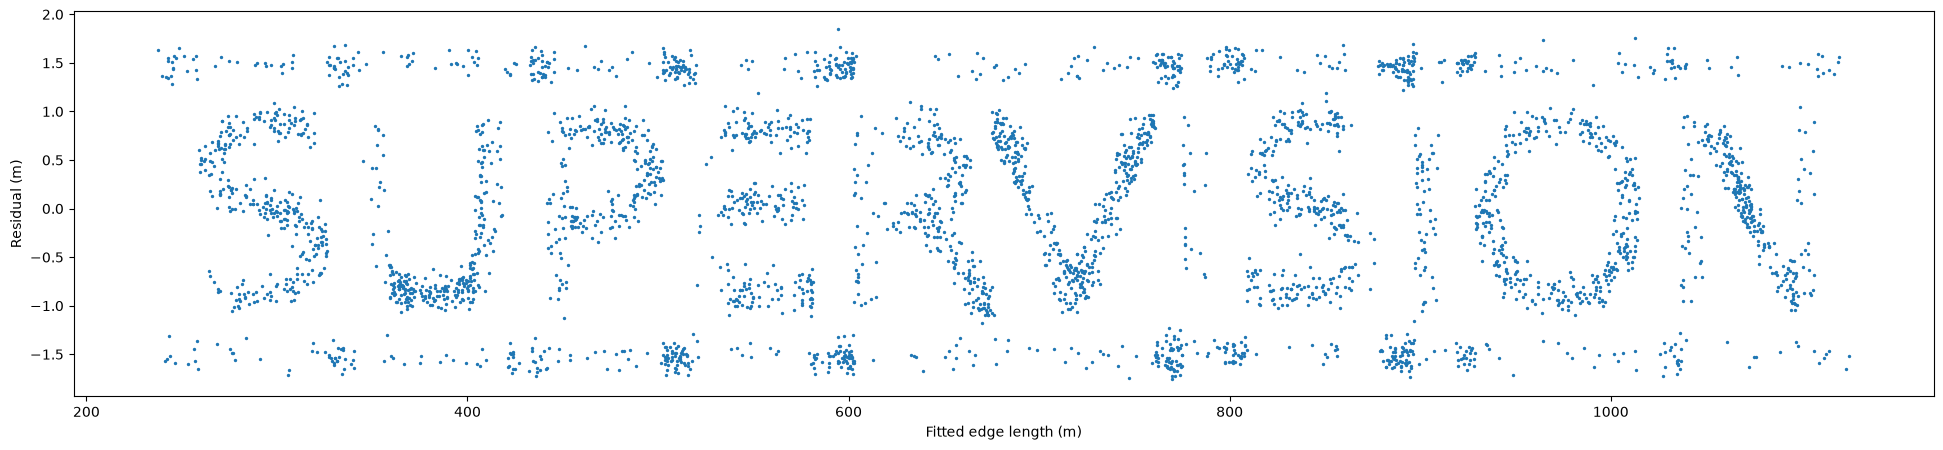

In [54]:
plt.figure(figsize=(24, 5))
plt.scatter(res.fittedvalues, res.resid, s=2)
plt.xlabel("Fitted edge length (m)")
plt.ylabel("Residual (m)")
plt.savefig("fry-ndship/figures/residuals.png",
            dpi=150, bbox_inches="tight")
plt.show()

### Attempts and result

We tried two models, both with an intercept, and plotted residuals against fitted edge length:

| Attempt | Predictors | In-sample R² | Word in residuals | Platform result |
|---|---|---|---|---|
| 1 | `long_side_m`, estimated `short_m` | 0.9983673004221523 (approximately 99.83673%) | REGRESSION | `SIGMOID_REGRESSION` was rejected |
| 2 | `long_side_m`, estimated `short_m`, `ditch_m` | 0.9999843184785999 (approximately 99.99843%) | SUPERVISION | `SIGMOID_SUPERVISION` was accepted |

Adding `ditch_m` refitted all coefficients together. The long-side and short-side coefficients changed from approximately 1.9 to approximately 0.9, and the ditch coefficient was approximately 1.0. This changed both the fitted values and the residuals while the measured edge lengths stayed the same.

Using the rounded coefficients from the saved output, the accepted model is approximately:

`predicted edge_m = -0.001098 + 0.900019 * long_side_m + 0.900023 * short_m + 0.999980 * ditch_m`

Each dot in the graph represents one field:

- **X-axis:** fitted (predicted) edge length in metres, from `res.fittedvalues`.
- **Y-axis:** residual in metres, calculated as `measured edge_m - predicted edge_m`, from `res.resid`.

The current plot spells **SUPERVISION**. The platform accepted **`SIGMOID_SUPERVISION`**, as confirmed after submission.

The earlier REGRESSION result shows that a high R² and a readable residual pattern alone were insufficient to establish the accepted answer. Residuals depend on which predictors the model includes.
